# Student Social Media & Wellbeing: Regression Model

Notebook này trình bày toàn bộ quy trình xây dựng mô hình: khảo sát dữ liệu,
kiểm tra chất lượng, so sánh mô hình bằng cross-validation, đánh giá trên
holdout, diễn giải mức ảnh hưởng của từng biến và ablation `Stress_Level`.
Điểm `Mental_Health_Score` là điểm khảo sát, không phải chẩn đoán y tế.

**Câu hỏi:** Thói quen mạng xã hội, giấc ngủ và học tập dự đoán điểm sức khỏe
tinh thần tốt đến mức nào, và biến nào đóng góp nhiều nhất?

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "app").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from app.features import CATEGORICAL_FEATURES, FEATURE_COLUMNS, NUMERIC_FEATURES
from app.train import (
    DEFAULT_ARTIFACT_PATH,
    DEFAULT_DATA_PATH,
    DEFAULT_METRICS_PATH,
    load_dataset,
    prepare_dataset,
    run_stress_ablation,
    save_artifacts,
    train_model,
)

pd.set_option("display.max_columns", None)

## 1. Đọc và khảo sát dữ liệu

In [2]:
data = load_dataset(DEFAULT_DATA_PATH)
print(f"Kích thước: {data.shape[0]:,} dòng x {data.shape[1]} cột")
display(data.head())
display(data.dtypes.to_frame("dtype"))
display(data.isna().sum().to_frame("missing"))
display(data.describe(include="all").T)

Kích thước: 5,000 dòng x 13 cột


,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


,dtype
Age,int64
Gender,str
Country,str
Academic_Level,str
Most_Used_Platform,str
Purpose_Of_Use,str
Avg_Daily_Usage_Hours,float64
Daily_Unlocks,int64
Study_Hours,float64
Physical_Activity_Hours,float64


,missing
Age,0
Gender,0
Country,0
Academic_Level,0
Most_Used_Platform,0
Purpose_Of_Use,0
Avg_Daily_Usage_Hours,0
Daily_Unlocks,0
Study_Hours,0
Physical_Activity_Hours,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,5000.0,NaN,NaN,NaN,20.8218,1.73662,18.0,19.0,21.0,22.0,24.0
Gender,5000,2,Male,2635,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,5000,111,Other,1880,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Academic_Level,5000,3,Undergraduate,3632,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Most_Used_Platform,5000,12,Instagram,1130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Purpose_Of_Use,5000,4,Entertainment,2552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Avg_Daily_Usage_Hours,5000.0,NaN,NaN,NaN,5.07846,1.653913,1.0,3.8,5.0,6.3,8.8
Daily_Unlocks,5000.0,NaN,NaN,NaN,171.4526,42.858254,62.0,140.0,171.0,204.0,273.0
Study_Hours,5000.0,NaN,NaN,NaN,3.00842,1.637018,0.3,1.5,2.8,4.2,8.3
Physical_Activity_Hours,5000.0,NaN,NaN,NaN,1.751,0.668398,-0.4,1.3,1.7,2.2,4.1


In [3]:
negative_activity = int((data["Physical_Activity_Hours"] < 0).sum())
duplicate_rows = int(data.duplicated().sum())
country_counts = data["Country"].value_counts()
other_country = int(country_counts.get("Other", 0))

print(f"Dòng trùng: {duplicate_rows}")
print(f"Physical_Activity_Hours âm: {negative_activity}")
print(f"Số quốc gia: {data['Country'].nunique()} (Other: {other_country} dòng)")
print(
    "Khoảng target: "
    f"{data['Mental_Health_Score'].min():.1f} - "
    f"{data['Mental_Health_Score'].max():.1f}"
)
display(country_counts.head(10).to_frame("rows"))

Dòng trùng: 2
Physical_Activity_Hours âm: 10
Số quốc gia: 111 (Other: 1880 dòng)
Khoảng target: 3.6 - 9.4


,rows
Country,
Other,1880
India,389
USA,355
Canada,230
Australia,198
UK,185
Germany,136
Mexico,94
Turkey,94


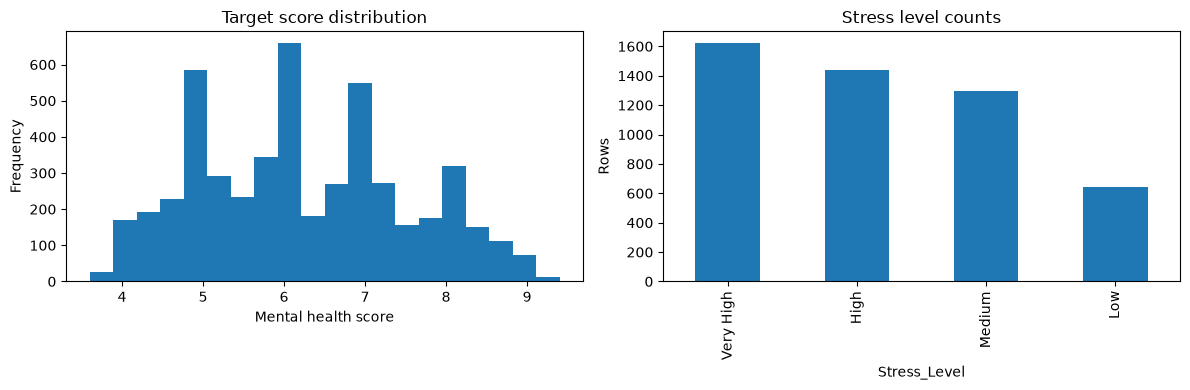

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
data["Mental_Health_Score"].plot(
    kind="hist", bins=20, ax=axes[0], title="Target score distribution"
)
data["Stress_Level"].value_counts().plot(
    kind="bar", ax=axes[1], title="Stress level counts"
)
axes[0].set_xlabel("Mental health score")
axes[1].set_ylabel("Rows")
plt.tight_layout()
plt.show()

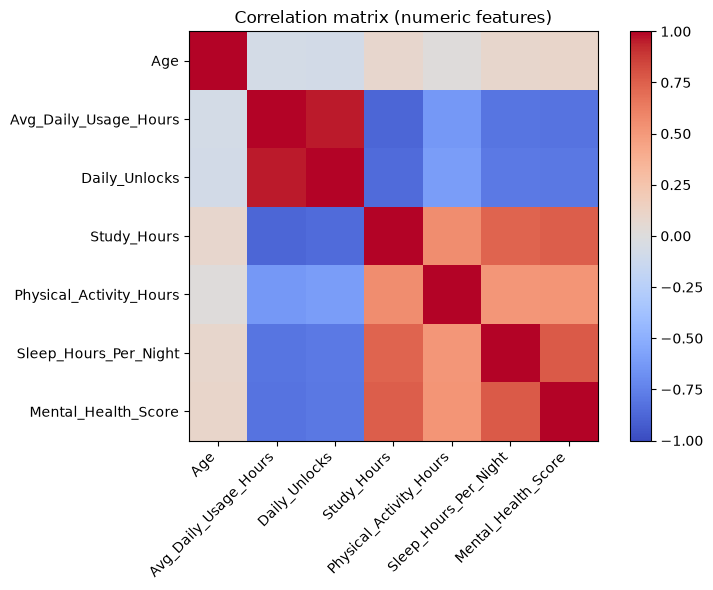

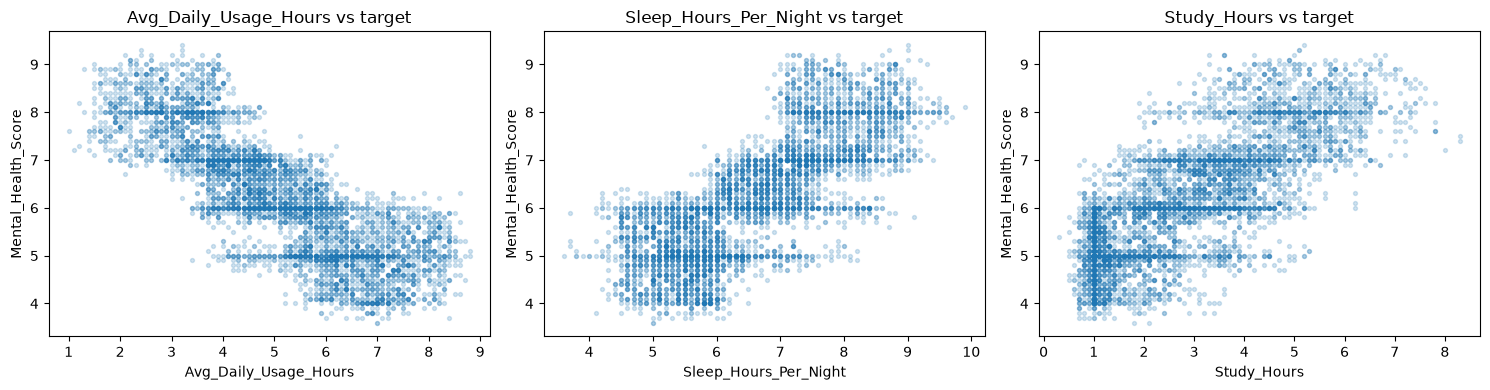

,mean,count
Stress_Level,,
Low,7.840217,644
Medium,7.135907,1295
High,6.025417,1440
Very High,5.051326,1621


,mean,count
Most_Used_Platform,,
KakaoTalk,5.983333,36
WeChat,6.494444,36
VKontakte,7.002500,40
LINE,8.024000,50
WhatsApp,5.578286,175
Snapchat,6.123095,420
Twitter,6.346753,462
YouTube,6.216497,491
LinkedIn,6.482600,523


In [5]:
numeric_columns = [
    "Age",
    "Avg_Daily_Usage_Hours",
    "Daily_Unlocks",
    "Study_Hours",
    "Physical_Activity_Hours",
    "Sleep_Hours_Per_Night",
    "Mental_Health_Score",
]
corr = data[numeric_columns].corr()

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_columns)))
ax.set_xticklabels(numeric_columns, rotation=45, ha="right")
ax.set_yticks(range(len(numeric_columns)))
ax.set_yticklabels(numeric_columns)
ax.set_title("Correlation matrix (numeric features)")
fig.colorbar(image, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(
    axes,
    ["Avg_Daily_Usage_Hours", "Sleep_Hours_Per_Night", "Study_Hours"],
):
    ax.scatter(data[column], data["Mental_Health_Score"], alpha=0.2, s=8)
    ax.set_xlabel(column)
    ax.set_ylabel("Mental_Health_Score")
    ax.set_title(f"{column} vs target")
plt.tight_layout()
plt.show()

display(
    data.groupby("Stress_Level")["Mental_Health_Score"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)
display(
    data.groupby("Most_Used_Platform")["Mental_Health_Score"]
    .agg(["mean", "count"])
    .sort_values("count")
)

### Nhận xét dữ liệu

- `Avg_Daily_Usage_Hours` tương quan âm mạnh với điểm (−0.82);
  `Sleep_Hours_Per_Night` (0.77) và `Study_Hours` (0.75) tương quan dương mạnh.
- `Stress_Level` vừa liên quan tới điểm vừa liên quan tới usage/sleep, nên không
  thể đọc quan hệ nhân quả từ tương quan.
- `Country` có 111 giá trị nhưng 1.880 dòng là `"Other"`, nên mô hình khó học
  khác biệt giữa các nước cụ thể.
- Một số nền tảng (ví dụ `LINE`) có điểm trung bình cao nhưng rất ít mẫu; không
  nên kết luận từ nhóm nhỏ.
- Dữ liệu có dấu hiệu tổng hợp/khảo sát: quan hệ rất mạnh và đều, nên R² cao
  không đồng nghĩa mô hình dùng được ngoài phân phối.

## 2. Tiền xử lý và so sánh mô hình

Mỗi ứng viên dùng cùng một `ColumnTransformer`: numeric passthrough, one-hot cho
biến phân loại (`handle_unknown="ignore"`), và chặn giá trị vận động âm về 0.
Việc fit preprocessing nằm trong pipeline nên chỉ diễn ra trên tập train của
từng fold — không leakage. Mô hình cuối được chọn bằng 5-fold CV trên tập train;
holdout 20% chỉ dùng để báo cáo.

In [6]:
(
    model,
    metrics,
    evaluation,
    cleaning_report,
    cv_table,
    selected_model,
    feature_importance,
) = train_model(data)

print("Selected:", selected_model)
print("Cleaning:", cleaning_report)
for name, value in metrics.items():
    print(f"{name.upper()}: {value:.4f}")
display(cv_table.round(4))

Selected: random_forest
Cleaning: {'negative_physical_activity_values_clipped': 10}
MAE: 0.2854
RMSE: 0.3948
R2: 0.9101


,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
model,,,,,,
random_forest,0.3069,0.0092,0.4166,0.0118,0.8918,0.0075
hist_gradient_boosting,0.3162,0.0093,0.4223,0.0121,0.8888,0.0079
linear_regression,0.4730,0.0111,0.6035,0.0127,0.7732,0.0104
baseline_dummy,1.0556,0.0199,1.2690,0.0248,-0.0017,0.0011


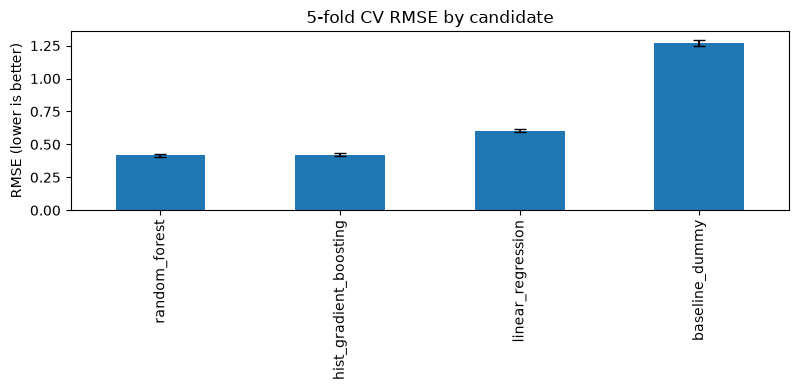

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
cv_table["rmse_mean"].plot(
    kind="bar",
    yerr=cv_table["rmse_std"],
    ax=ax,
    title="5-fold CV RMSE by candidate",
    capsize=4,
)
ax.set_ylabel("RMSE (lower is better)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

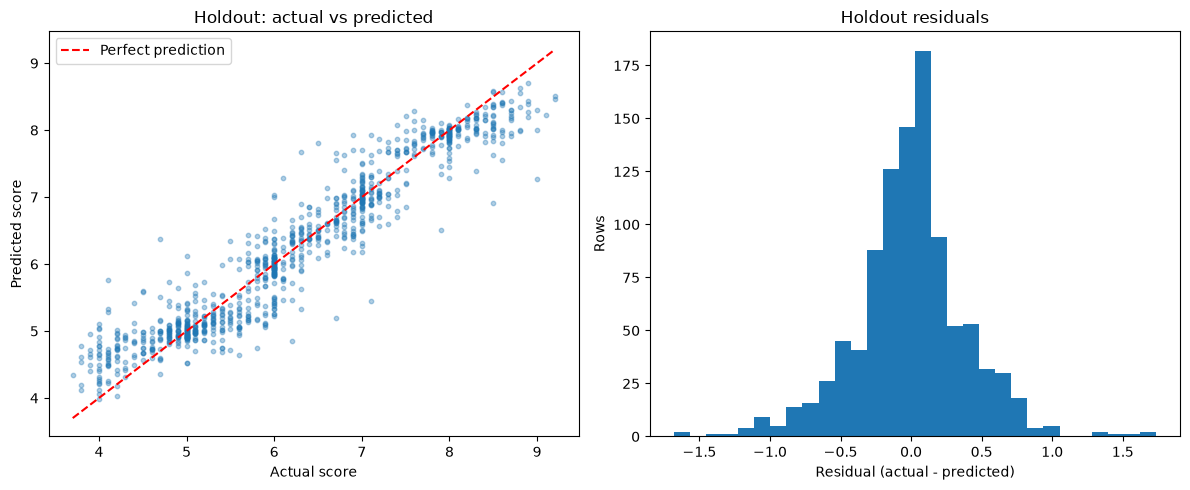

Residual mean: -0.0022
Residual std: 0.3950


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(evaluation["actual"], evaluation["predicted"], alpha=0.35, s=10)
limits = [evaluation.min().min(), evaluation.max().max()]
axes[0].plot(limits, limits, "--", color="red", label="Perfect prediction")
axes[0].set(
    xlabel="Actual score",
    ylabel="Predicted score",
    title="Holdout: actual vs predicted",
)
axes[0].legend()

residuals = evaluation["actual"] - evaluation["predicted"]
axes[1].hist(residuals, bins=30)
axes[1].set(
    xlabel="Residual (actual - predicted)",
    ylabel="Rows",
    title="Holdout residuals",
)
plt.tight_layout()
plt.show()

print(f"Residual mean: {residuals.mean():.4f}")
print(f"Residual std: {residuals.std():.4f}")

,feature,importance
0,Avg_Daily_Usage_Hours,0.8765
1,Sleep_Hours_Per_Night,0.3412
2,Country,0.2349
3,Daily_Unlocks,0.0942
4,Most_Used_Platform,0.0495
5,Study_Hours,0.0396
6,Age,0.0358
7,Physical_Activity_Hours,0.0296
8,Purpose_Of_Use,0.0180
9,Academic_Level,0.0171


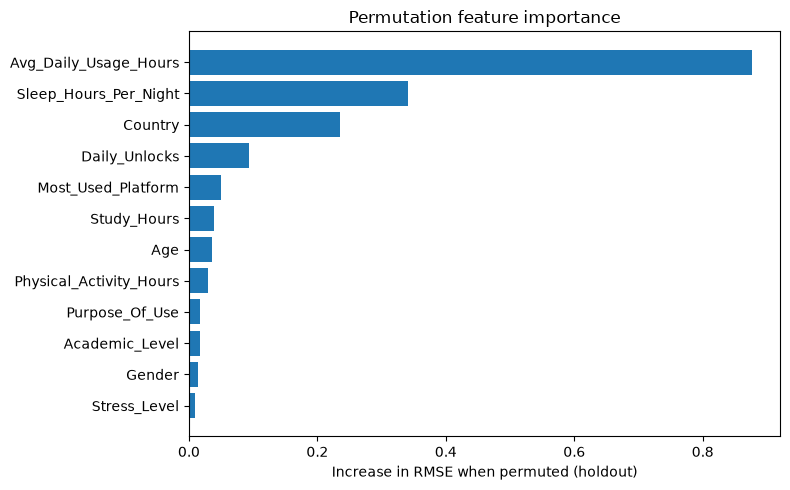

In [9]:
importance_frame = pd.DataFrame(feature_importance)
display(importance_frame.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
plot_frame = importance_frame.iloc[::-1]
ax.barh(plot_frame["feature"], plot_frame["importance"])
ax.set_xlabel("Increase in RMSE when permuted (holdout)")
ax.set_title("Permutation feature importance")
plt.tight_layout()
plt.show()

In [10]:
ablation = run_stress_ablation(data)
comparison = pd.DataFrame(
    [
        {"variant": "with_stress", **metrics},
        {"variant": "without_stress", **ablation["metrics"]},
    ]
).set_index("variant")
display(comparison.round(4))
print("Ablation selected model:", ablation["selected_model"])

,mae,rmse,r2
variant,,,
with_stress,0.2854,0.3948,0.9101
without_stress,0.2855,0.3978,0.9088


Ablation selected model: random_forest


## 3. Lưu model cho API

Chạy cell này để tạo/cập nhật `artifacts/mental_health_model.joblib` và
`artifacts/metrics.json` với metadata mới (CV, importance, ablation).

In [11]:
metadata = save_artifacts(
    model=model,
    metrics=metrics,
    training_rows=len(data),
    cleaning_report=cleaning_report,
    cv_table=cv_table,
    selected_model=selected_model,
    feature_importance=feature_importance,
    stress_ablation=ablation,
    artifact_path=DEFAULT_ARTIFACT_PATH,
    metrics_path=DEFAULT_METRICS_PATH,
)
metadata

{'model_version': '1.1.0',
 'target_column': 'Mental_Health_Score',
 'selected_model': 'random_forest',
 'feature_columns': ['Age',
  'Gender',
  'Country',
  'Academic_Level',
  'Most_Used_Platform',
  'Purpose_Of_Use',
  'Avg_Daily_Usage_Hours',
  'Daily_Unlocks',
  'Study_Hours',
  'Physical_Activity_Hours',
  'Sleep_Hours_Per_Night',
  'Stress_Level'],
 'metrics': {'mae': 0.285447, 'rmse': 0.39477, 'r2': 0.910131},
 'cv_results': [{'model': 'random_forest',
   'mae_mean': 0.306929,
   'mae_std': 0.009213,
   'rmse_mean': 0.416572,
   'rmse_std': 0.011787,
   'r2_mean': 0.891836,
   'r2_std': 0.007482},
  {'model': 'hist_gradient_boosting',
   'mae_mean': 0.31622,
   'mae_std': 0.009299,
   'rmse_mean': 0.422266,
   'rmse_std': 0.012099,
   'r2_mean': 0.888848,
   'r2_std': 0.007894},
  {'model': 'linear_regression',
   'mae_mean': 0.473043,
   'mae_std': 0.011126,
   'rmse_mean': 0.603468,
   'rmse_std': 0.012742,
   'r2_mean': 0.773224,
   'r2_std': 0.010436},
  {'model': 'baselin

## 4. Kết luận và hạn chế

- Mô hình được CV chọn (với dữ liệu hiện tại là `random_forest`) đạt R² holdout
  khoảng 0.91; Linear Regression chỉ khoảng 0.77 — mô hình phi tuyến phù hợp hơn.
- `Avg_Daily_Usage_Hours` và `Sleep_Hours_Per_Night` đóng góp nhiều nhất;
  `Stress_Level` gần như dư thừa khi đã có usage/sleep (xem ablation).
- `Country` có permutation importance khá cao; cẩn thận vì nhiều nước gộp vào
  `"Other"` và dữ liệu có thể là tổng hợp.
- Đây là tương quan trên dữ liệu khảo sát, không phải quan hệ nhân quả; mô hình
  không dùng để chẩn đoán, sàng lọc hay tư vấn sức khỏe tinh thần.
- Dự đoán ngoài phân phối (quốc gia mới, độ tuổi ngoài 18–24) không được đảm bảo.